KOUASSI Cédric

Comprendre le comportement des clients est devenu essentiel pour les entreprises qui souhaitent adapter leurs stratégies commerciales et anticiper les besoins des consommateurs. Les habitudes d’achat, telles que la fréquence des achats, le montant dépensé, le type de produits achetés, ainsi que certaines caractéristiques des clients, permettent d’identifier des tendances et de mieux cibler les actions marketing.
Le dataset Customer Purchase Behaviour, disponible sur Kaggle, rassemble des informations sur les transactions de clients, incluant le montant des achats, la fréquence, les catégories de produits et quelques données démographiques. Ce jeu de données offre l’opportunité d’analyser les facteurs qui influencent le montant des achats et de construire un modèle capable de prédire combien un nouveau client pourrait dépenser.
La problématique centrale de ce projet est la suivante : quels sont les facteurs qui influencent le montant des achats des clients et comment peut-on prédire le montant qu’un nouveau client dépensera ?
L’objectif est donc d’explorer ces données, de comprendre les relations entre les différentes variables et le montant des achats, et de construire un modèle de régression permettant de réaliser des prédictions fiables pour de nouveaux clients.


In [ ]:
##Exploration des données


In [ ]:
## pandas pour la manipulation de données
import pandas as pd

In [ ]:
df=pd.read_csv("/content/shopping_behavior_updated.csv") # le chemin pour acceder au fichier

In [ ]:
# Importation des bibliothèques principales
## numpy: pour les operation mathematique
## matpolit as et import seaborn as: pour la visulaisation
import pandas as pd
import numpy as np  # operations mathematiques
import matplotlib.pyplot as plt  ## pour la visualisation
import seaborn as sns  # visualisation

# Pour le machine learning
from sklearn.linear_model import LinearRegression # regression lineaire
from sklearn.model_selection import train_test_split # sparation de train/ test
from sklearn.preprocessing import LabelEncoder, StandardScaler # encodage et standardisation
from sklearn.metrics import r2_score, mean_squared_error # encodage des variables catégorielles

In [ ]:
df.shape #indique la taille du dataframe ligne et colonnes


(3900, 18)

In [ ]:
df.head(10) # les 10 premieres lignes

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,95.88,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,40.30,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,85.05,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,50.59,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,58.44,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually
5,6,46,Male,Sneakers,Footwear,71.06,Wyoming,M,White,Summer,2.9,Yes,Standard,Yes,Yes,14,Venmo,Weekly
6,7,63,Male,Shirt,Clothing,74.31,Montana,M,Gray,Fall,3.2,Yes,Free Shipping,Yes,Yes,49,Cash,Quarterly
7,8,27,Male,Shorts,Clothing,80.07,Louisiana,L,Charcoal,Winter,3.2,Yes,Free Shipping,Yes,Yes,19,Credit Card,Weekly
8,9,26,Male,Coat,Outerwear,50.44,West Virginia,L,Silver,Summer,2.6,Yes,Express,Yes,Yes,8,Venmo,Annually
9,10,57,Male,Handbag,Accessories,60.78,Missouri,M,Pink,Spring,4.8,Yes,2-Day Shipping,Yes,Yes,4,Cash,Quarterly


In [ ]:
df.info() # afficher les types de colonnes, le nombre de valeurs non nulles et la memoire utilisée
df.describe() # fournit des statistique descriptives pour les colonnes numériques: moyenne, min, max...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   float64
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,76.822410,3.749949,25.351538
std,1125.977353,15.207589,25.206396,0.716223,14.447125
min,1.000000,18.000000,20.560000,2.500000,1.000000
25%,975.750000,31.000000,58.105000,3.100000,13.000000
50%,1950.500000,44.000000,73.540000,3.700000,25.000000
75%,2925.250000,57.000000,91.672500,4.400000,38.000000
max,3900.000000,70.000000,190.570000,5.000000,50.000000


In [ ]:
#Constat : Les clients ont en moyenne 44 ans : le public cible semble être des adultes actifs.Le montant moyen d’achat tourne autour de 60 USD, mais la forte dispersion suggère des comportements d’achat hétérogènes (petits et gros acheteurs).Les avis clients sont globalement positifs, ce qui reflète une satisfaction correcte mais améliorable.Les achats précédents montrent une clientèle variée en termes de fidélité : certains clients reviennent régulièrement, d’autres très rarement.Les nombreuses variables qualitatives (genre, catégorie, saison, etc.) offrent de bonnes possibilités d’analyse croisée pour comprendre les facteurs influençant les ventes.#

In [ ]:
df.isna().sum() # compte le nombre de valeur manquantes par colonne

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [ ]:
##CONSTAT: aucune valeur ne manque ###


In [ ]:
# Vérifier les doublons
df.duplicated().sum() # compte le nombre de ligne dupliquées dans le dataframe

np.int64(0)

In [ ]:
## constat :  il n’y a aucun doublon dans le DataFrame.##""


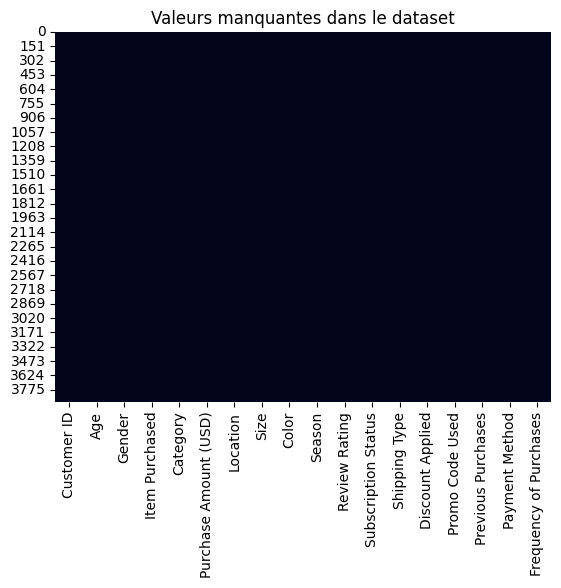

In [ ]:
# Visualisation des valeurs manquantes
sns.heatmap(df.isna(), cbar=False) # crée une heatmap où chaque cellule indique si une valeur est manquante
plt.title("Valeurs manquantes dans le dataset") # ajoute un titre au graphique pour contextualiser
plt.show() # afficher la figure matplotlib à l'ecran

In [ ]:
##Constat : D’après la visualisation ci-dessus, on peut observer qu’il n’y a aucun schéma particulier qui se dégage. En effet, il n’y a aucune donnée manquante.###


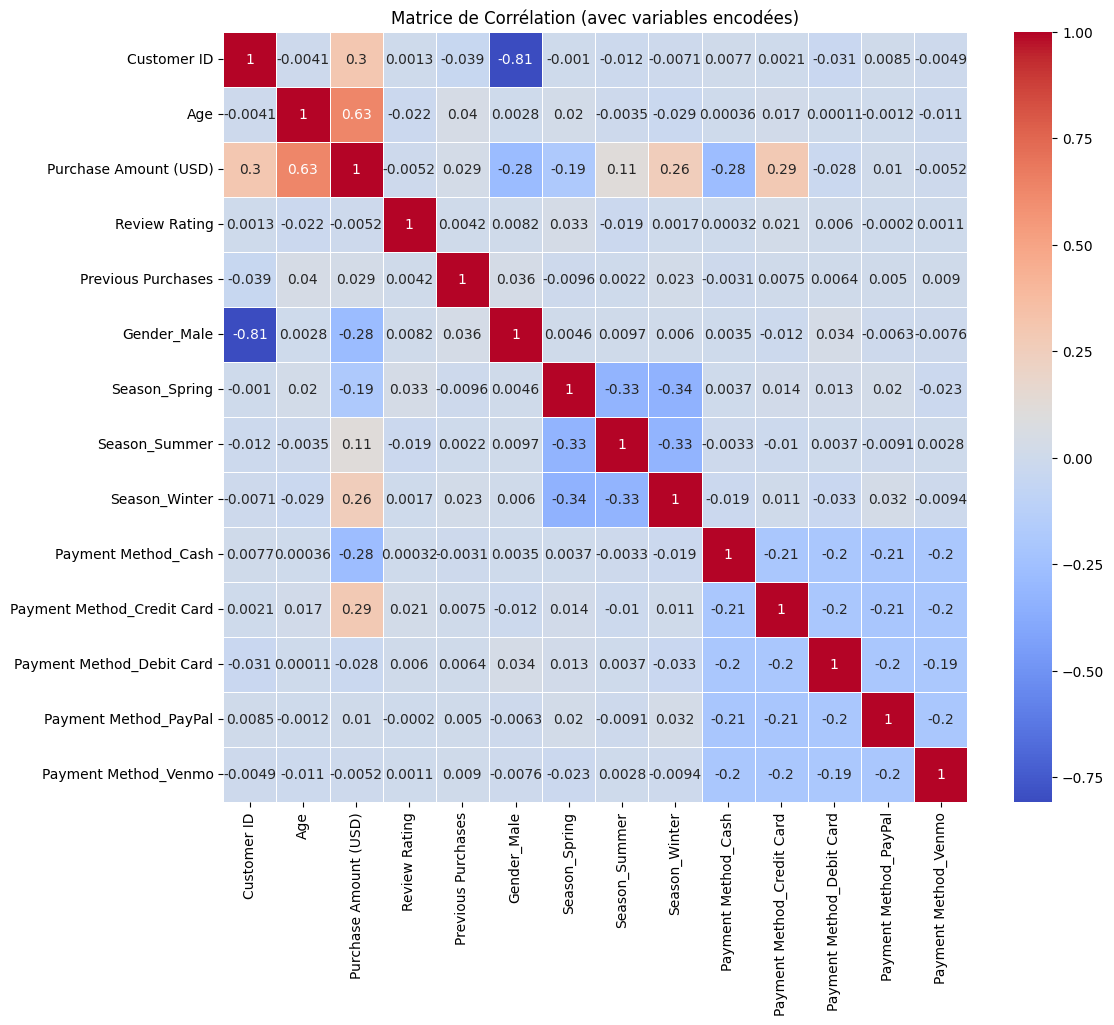

In [ ]:
# 1. Encodage des variables catégorielles

cols_to_encode = ["Gender", "Season", "Payment Method"]
#Déclare la liste des colonnes catégorielles que l'on souhaite encoder en variables indicatrices.

df_encoded = pd.get_dummies(df, columns=cols_to_encode, drop_first=True)
# -> Transforme les colonnes catégorielles en colonnes numériques (one-hot / dummy variables).
#    drop_first=True supprime la première modalité de chaque variable pour éviter la redondance
#    (et réduire la multicolinéarité dans les modèles linéaires).

# 2. Calcul de la matrice de corrélation (toutes variables numériques)

correlation_matrix = df_encoded.corr(numeric_only=True)
#Calcule la matrice de corrélation entre toutes les colonnes numériques du DataFrame encodé.
#    numeric_only=True s'assure qu'on ne tente pas de corréler des colonnes non numériques.

# 3. Visualisation de la matrice de corrélation
plt.figure(figsize=(12,10))
# -> Crée une nouvelle figure matplotlib de taille 12x10 pouces pour un affichage lisible.
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=0.5)
Trace la heatmap (carte thermique) de la matrice de corrélation.
#    annot=True affiche les valeurs numériques dans chaque cellule.
#    cmap="coolwarm" choisit une palette où le bleu/rouge indique négatif/positif.
#    linewidths=0.5 dessine des séparations fines entre les cellules pour améliorer la lisibilité.
plt.title("Matrice de Corrélation (avec variables encodées)")
# -> Ajoute un titre explicite à la figure pour contextualiser le graphique
plt.show()
Affiche la figure à l'écran (ou dans le notebook).

In [ ]:
##constat :
##1. Facteur le plus influent##

Âge (+0.63)
Les clients plus âgés dépensent davantage. C’est la variable ayant la relation la plus forte avec le montant des achats.

##2. Facteurs avec influence modérée ou faible

Paiement par Carte de Crédit (+0.29)
Les clients qui paient par carte de crédit dépensent légèrement plus.

Saison Hiver (+0.26)
Les dépenses augmentent légèrement durant la saison hivernale.

##3. Facteur à faible impact

Genre Masculin (−0.28)
Les hommes dépensent un peu moins que les femmes, mais l’impact reste faible.##


In [ ]:
##Etude de la Corrélations entre la variable explicative et les autres  variables


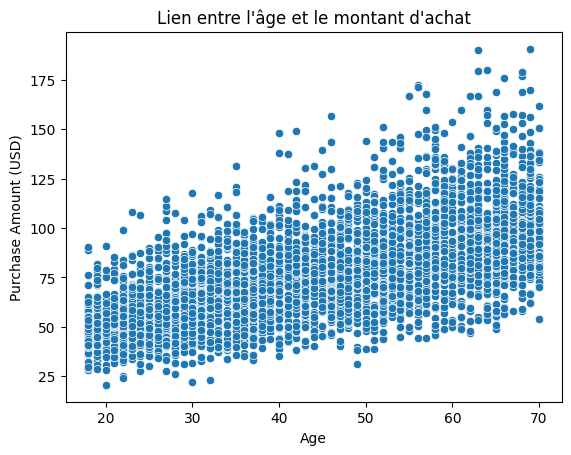

In [ ]:
sns.scatterplot(x="Age", y="Purchase Amount (USD)", data=df) # créer des nuages de points montrant la rélation entre l'age et le montant d'achat
plt.title("Lien entre l'âge et le montant d'achat") # ajouter un titre au graphique
plt.show() #afficher la figure matplotlib à l'écran

In [ ]:
##constat : les point sont bien aligner a peut pres au niveau de la meme zone ce qui traduit une assez forte correlation entre le montant et l'age , plus l'age augmente plus le montant d'achat augmente


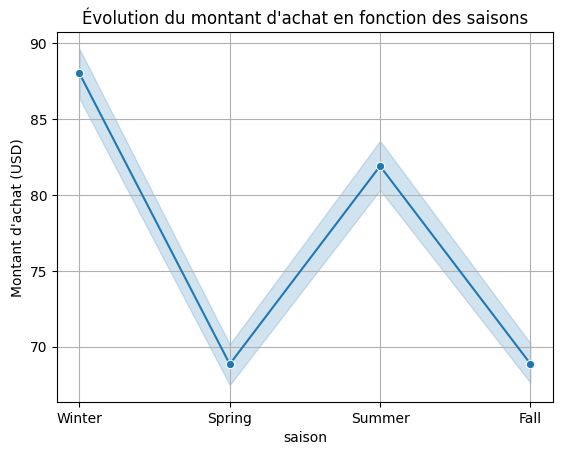

In [ ]:
import matplotlib.pyplot as plt
sns.lineplot(x="Season", y="Purchase Amount (USD)", data=df, marker="o") # evolution du monatant d'achat en focntion des saisons

plt.title("Évolution du montant d'achat en fonction des saisons") # titre du graphique
plt.xlabel("saison")
plt.ylabel("Montant d'achat (USD)")
plt.grid(True)
plt.show()

<Axes: xlabel='Purchase Amount (USD)', ylabel='Count'>

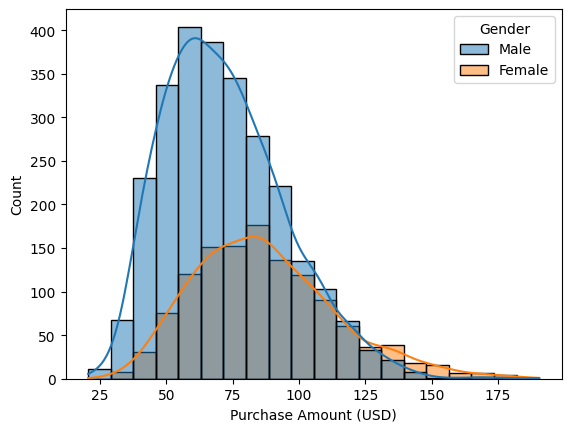

In [ ]:
sns.histplot(data=df, x="Purchase Amount (USD)", hue="Gender", bins=20, kde=True)
# crée un histogramme montrant la repartition du montant d'achat
#hue=gender: separe les distributions selon le genre
#bins=20 nombre de bins pour l'axe X
# kde=true ajoute la courbe de densité pour visualiser la distribution

In [ ]:
#Modélisation : Régression linéaire

In [ ]:
### CONSTAT  L'histogramme montre que les femmes réalisent en moyenne des achats plus importants que les hommes, même si la fréquence d’achat masculine reste plus élevée sur les montants moyens. Cela reflète une tendance où certains segments féminins dépensent davantage lors d’achats ciblés (ex. : mode, cadeaux, produits de qualité).


In [ ]:
df.columns # affiche la liste de toutes les colonnes du dataFrame

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Shipping Type',
       'Discount Applied', 'Promo Code Used', 'Previous Purchases',
       'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [ ]:
X = df[["Age", "Gender", "Season","Payment Method" ,"Location","Payment Method"]] # variables choisis pour la modelisation
y = df["Purchase Amount (USD)"] # varibale cible qui est le montant d'achat en USD

In [ ]:
from sklearn.model_selection import train_test_split # importation de la fonction permettant de séparer le dataset en ensemble d'entrainement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# separe les données
# x_train/y_train: données d'entrainement
#x_tes/y_test: données de test
# test_size=0.2 proportion des données resrevée au test
#random_state=42 assure la reproductibilité de la séparation

In [ ]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
# encodage des variables categorielles en variables numeriques pour l'ensemble d'entrainement
#drop_first: evite la multicolinéarité en supprimant la premiere categorie de chaque variable
X_test_encoded = pd.get_dummies(X_test, drop_first=True)
# encodage des variable pour l'ensemble de test

In [ ]:
from sklearn.linear_model import LinearRegression # importation du modele de regression linéaire depuis scikit-learn
model = LinearRegression() # création d'une instance du modele de regression lineaire
model.fit(X_train_encoded, y_train) # entrainement du modele sur les données d'entrainement

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_encoded) # prediction des valeurs cibles pour l'ensemble de test à l'aide du modele entrainé
# y_pred: contient les monatant d'acahta predits

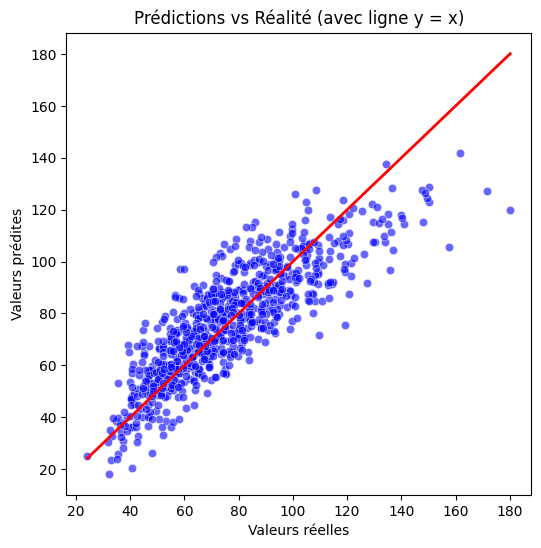

In [ ]:
plt.figure(figsize=(6,6)) # definit la taille de la figure
sns.scatterplot(x=y_test, y=y_pred, color="blue", alpha=0.6) # crée une nuage de point des valeurs réelles et prédites
# color=blue couleur des points
#alpha=0.6 transparence pour mieux visualiser la densité des points
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2) # trace une ligne rouge y=X representent la prediction parfaite et cela permet de visualiser l'ecart entre les valeurs réelles et prédites
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Prédictions vs Réalité (avec ligne y = x)")
plt.show()

In [ ]:
##Constat : Les points sont bien alignés autour de la ligne rouge y = x, ce qui montre une bonne corrélation entre les valeurs réelles et prédites.
Toutefois, on observe une dispersion croissante pour les valeurs élevées :
➜ Le modèle est moins précis pour les grandes valeurs (phénomène d’hétéroscédasticité).


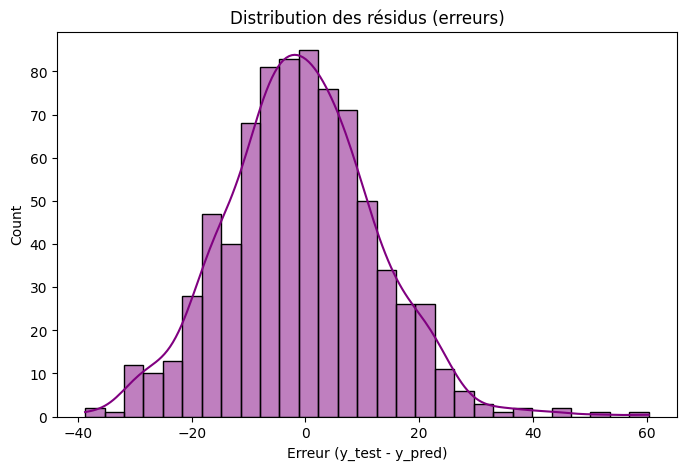

In [ ]:
residus = y_test - y_pred # calcul des residus: difference entre les valeurs réels et prédites

plt.figure(figsize=(8,5)) # definit la taille de la figure
sns.histplot(residus, kde=True, color='purple') # crée un histogramme des résidus
#kde=True : ajoute la courbe de densité (Kernel Density Estimate)
## color='purple' : couleur de l'histogramme
plt.title("Distribution des résidus (erreurs)") # titre
plt.xlabel("Erreur (y_test - y_pred)")
plt.show()

In [ ]:
##Constat :
La distribution est centrée autour de 0, ce qui indique que le modèle ne présente pas de biais systématique (il ne surestime ni ne sous-estime de manière globale). La forme est assez proche d’une courbe en cloche (normale), ce qui est bon signe pour une régression linéaire. Cependant, la queue droite légèrement plus longue suggère la présence de quelques valeurs extrêmes où le modèle a surestimé la valeur réelle.


In [ ]:
comparison = pd.DataFrame({'Réel': y_test, 'Prédit': y_pred}) ## Crée un DataFrame comparant les valeurs réelles (y_test) et les valeurs prédites (y_pred)
print(comparison.head(10))
#Affiche les 10 premières lignes du tableau comparatif

        Réel      Prédit
839    60.96   69.204156
1717   69.18   60.480757
321    74.94   78.291852
3187  150.15  123.147100
2269   88.96   82.031594
366    78.46   86.475307
2644   43.71   43.225531
1749   79.76   63.444133
3605   90.69  105.030063
1096   85.30   92.201514


In [ ]:
##Constat :
Les valeurs prédites sont proches des valeurs réelles, mais il y a quelques écarts notables sur certains points (ex. 150.15 vs 123.15). Cela reflète un modèle globalement précis, mais avec des erreurs ponctuelles plus marquées pour certaines observations.


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
## Importation des métriques d'évaluation et de NumPy pour le calcul de la racine carrée

##evaluation du model ###
# R²
r2 = r2_score(y_test, y_pred) #Coefficient de détermination R² : indique la proportion de variance expliquée par le modèle

# MAE (Mean Absolute Error)
mae = mean_absolute_error(y_test, y_pred) #rreur moyenne absolue

# MSE (Mean Squared Error)
mse = mean_squared_error(y_test, y_pred) #erreur quadratique moyenne

# RMSE (Root Mean Squared Error)
rmse = np.sqrt(mse) #racine carrée du MSE, exprime l'erreur dans les mêmes unités que la variable cible
## Affiche les métriques d'évaluation du modèle
print("R² :", r2)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)

R² : 0.7113721115830215
MAE : 10.252548217091817
MSE : 173.16552877724044
RMSE : 13.159237393452571


In [ ]:
###Interprétation des métriques du modèle

Le modèle atteint un R² de 0.71, ce qui signifie qu’il explique 71 % de la variation du montant des achats. Cela montre une bonne capacité prédictive, même si une partie du comportement reste non expliquée.

Le MAE est de 10.25, indiquant qu’en moyenne, les prédictions s’écartent de la réalité d’environ 10 unités monétaires. Le RMSE de 13.16 confirme que l’erreur typique du modèle se situe autour de 13 unités, ce qui reste cohérent et raisonnable selon l’échelle des montants d’achat.

Le MSE de 173.17 révèle que certaines valeurs présentent des erreurs plus importantes, car cette métrique amplifie les écarts élevés. Globalement, le modèle offre une précision satisfaisante, mais peut être amélioré pour réduire les erreurs plus extrêmes et capturer davantage de variabilité.

In [ ]:
### CONCLUSION GENERAL

L’analyse montre que le montant des achats des clients est principalement influencé par l’âge, qui apparaît comme le facteur déterminant le plus fort. D’autres variables, comme le paiement
par carte de crédit et la saison hivernale, exercent une influence plus modérée, tandis que le genre présente un impact faible. Le modèle de
prédiction obtenu reproduit correctement les comportements d’achat, avec un R² de 0.71 indiquant une bonne capacité explicative et des erreurs de prédiction globalement raisonnables,
malgré quelques écarts ponctuels sur certaines observations. Les résidus sont globalement centrés autour de zéro, ce qui confirme l’absence de biais notable et la cohérence du modèle. Ainsi, il est
possible d’identifier les clients les plus susceptibles de dépenser davantage et d’estimer de manière fiable le montant qu’un nouveau client pourrait dépenser,
tout en gardant à l’esprit qu’une partie de la variabilité demeure liée à des facteurs non pris en compte.